# 01 — Exploratory data analysis

Chest X-Ray Images (Pneumonia), Kermany et al. 2018. What we check:
1. How many NORMAL vs PNEUMONIA images are in each official folder
2. What the images look like and how big they are
3. How many images each patient has (why we split by patient)
4. The train / val / test split we use (`data/splits/*.csv`) and whether patients leak between splits

Run from the repository root folder or from `notebooks/`. Set `DATA_DIR` to the folder that contains `train/`, `val/`, `test/`
(on Kaggle: `/kaggle/input/chest-xray-pneumonia/chest_xray`).

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd() if (Path.cwd() / "pneumonia").is_dir() else Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from PIL import Image

from pneumonia.splits import CLASS_NAMES, load_split, scan_folder

DATA_DIR = REPO_ROOT / "data" / "raw" / "chest_xray"
SPLITS_DIR = REPO_ROOT / "data" / "splits"
FIGURES_DIR = REPO_ROOT / "results" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

## 1. Official folders: class counts

In [2]:
official = pd.concat([scan_folder(DATA_DIR, s) for s in ("train", "val", "test")], ignore_index=True)
counts = official.pivot_table(index="source_split", columns="class_name", values="path", aggfunc="count")
counts = counts.loc[["train", "val", "test"]]
counts["total"] = counts.sum(axis=1)
counts["pneumonia share"] = (counts["PNEUMONIA"] / counts["total"]).round(3)
counts

class_name,NORMAL,PNEUMONIA,total,pneumonia share
source_split,,,,
train,1341,3875,5216,0.743
val,8,8,16,0.500
test,234,390,624,0.625


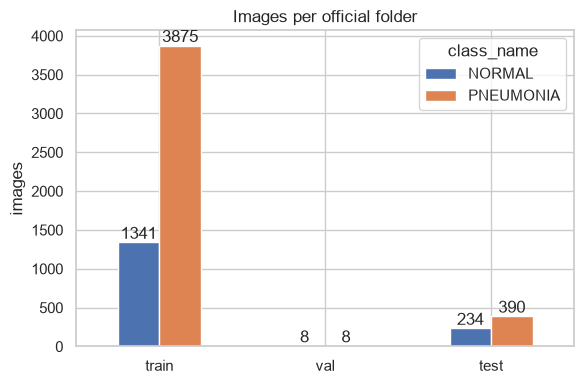

In [3]:
ax = counts[list(CLASS_NAMES)].plot.bar(figsize=(6, 4), rot=0, color=["#4C72B0", "#DD8452"])
ax.set(title="Images per official folder", xlabel="", ylabel="images")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_class_counts.png", dpi=150)
plt.show()

The official `val/` folder has only 16 images — far too few to choose the best epoch.
The classes are imbalanced (about 3 PNEUMONIA : 1 NORMAL), so we balance training batches with a weighted sampler and
report metrics beyond accuracy.

## 2. Sample images

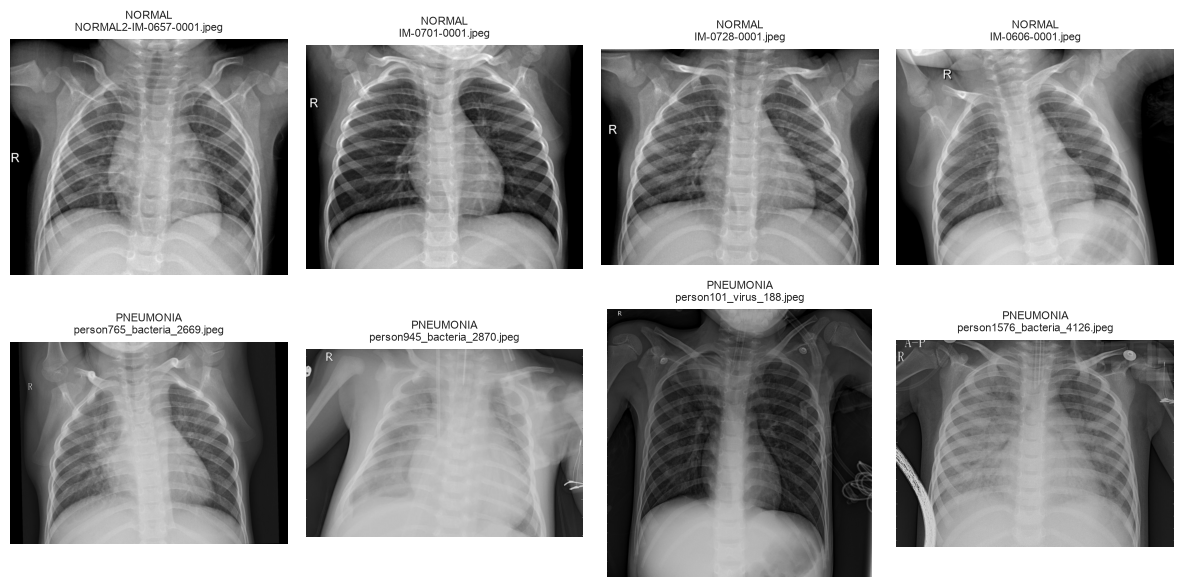

In [4]:
samples = official[official["source_split"] == "train"].groupby("class_name").sample(4, random_state=42)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, (_, row) in zip(axes.ravel(), samples.iterrows()):
    ax.imshow(Image.open(DATA_DIR / row["path"]).convert("L"), cmap="gray")
    ax.set_title(f"{row['class_name']}\n{Path(row['path']).name}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_samples.png", dpi=150)
plt.show()

## 3. Image sizes and colour modes

In [5]:
def image_info(path: str) -> dict:
    with Image.open(DATA_DIR / path) as img:
        return {"width": img.width, "height": img.height, "mode": img.mode}

sizes = pd.concat([official, pd.DataFrame([image_info(p) for p in official["path"]])], axis=1)
print(sizes["mode"].value_counts().to_string())
sizes.groupby("class_name")[["width", "height"]].describe().round(0)

mode
L      5573
RGB     283


width                                                        \
             count    mean    std    min     25%     50%     75%     max   
class_name                                                                 
NORMAL      1583.0  1686.0  305.0  912.0  1472.0  1654.0  1848.0  2916.0   
PNEUMONIA   4273.0  1195.0  285.0  384.0  1000.0  1160.0  1360.0  2772.0   

            height                                                        
             count    mean    std    min     25%     50%     75%     max  
class_name                                                                
NORMAL      1583.0  1379.0  343.0  496.0  1140.0  1323.0  1554.0  2713.0  
PNEUMONIA   4273.0   820.0  271.0  127.0   640.0   776.0   960.0  2304.0

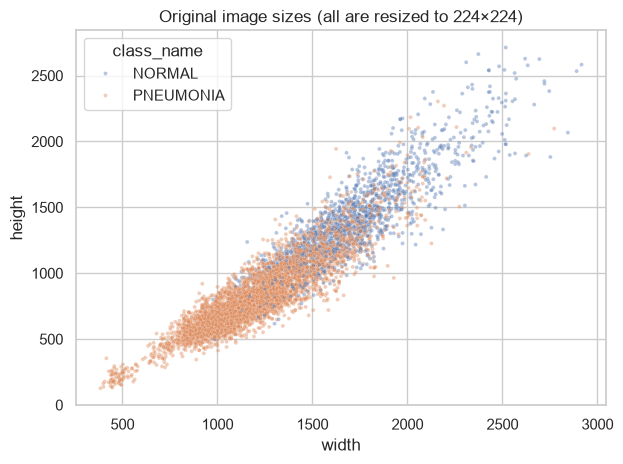

In [6]:
ax = sns.scatterplot(data=sizes, x="width", y="height", hue="class_name", s=8, alpha=0.4)
ax.set(title="Original image sizes (all are resized to 224×224)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_image_sizes.png", dpi=150)
plt.show()

Images come in very different sizes and some are stored as RGB although they are grayscale.
The data pipeline converts every image to 3 identical channels and resizes it to 224×224.

**Watch out:** NORMAL images are systematically larger than PNEUMONIA images (median about 1650×1320 vs 1160×780 px).
After resizing, this can leave traces such as different sharpness or aspect-ratio distortion, which a model could use
as a shortcut instead of looking at the lungs. Grad-CAM (ID-17) helps check that.

## 4. Images per patient

             count  mean   std  min  25%  50%  75%   max
class_name                                              
NORMAL      1219.0  1.11  0.45  1.0  1.0  1.0  1.0   4.0
PNEUMONIA   1642.0  2.36  2.05  1.0  1.0  2.0  3.0  30.0


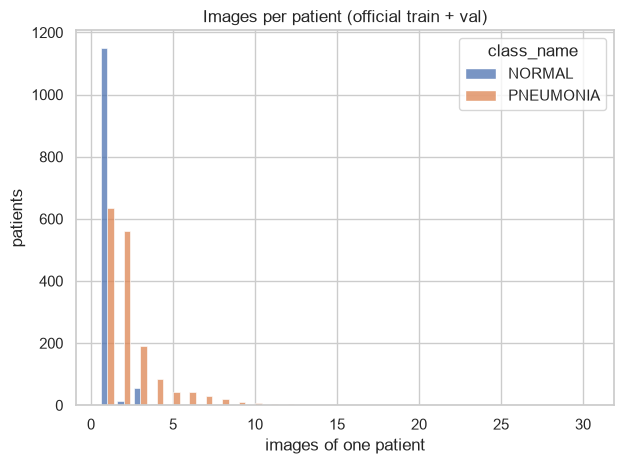

In [7]:
pool = official[official["source_split"] != "test"]
per_patient = pool.groupby(["class_name", "patient_id"]).size().rename("images").reset_index()
print(per_patient.groupby("class_name")["images"].describe().round(2).to_string())
ax = sns.histplot(data=per_patient, x="images", hue="class_name", discrete=True, multiple="dodge", shrink=0.8)
ax.set(title="Images per patient (official train + val)", xlabel="images of one patient", ylabel="patients")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_images_per_patient.png", dpi=150)
plt.show()

Many PNEUMONIA patients have several X-rays. If the same patient were in both train and val, the model could
recognise the person instead of the disease and the validation score would be too optimistic. That is why the split
keeps every patient in one group only.

## 5. Our split (`data/splits/`)

In [8]:
splits = {name: load_split(SPLITS_DIR, name) for name in ("train", "val", "test")}
summary = pd.DataFrame({
    name: {
        "images": len(df),
        "patients": df["patient_id"].nunique(),
        "NORMAL": (df["class_name"] == "NORMAL").sum(),
        "PNEUMONIA": (df["class_name"] == "PNEUMONIA").sum(),
        "pneumonia share": round((df["class_name"] == "PNEUMONIA").mean(), 3),
    }
    for name, df in splits.items()
}).T
summary

,images,patients,NORMAL,PNEUMONIA,pneumonia share
train,4447.0,2441.0,1147.0,3300.0,0.742
val,785.0,420.0,202.0,583.0,0.743
test,624.0,427.0,234.0,390.0,0.625


In [9]:
def shared_patients(a: str, b: str) -> set:
    return set(splits[a]["patient_id"]) & set(splits[b]["patient_id"])

print("train & val patients :", len(shared_patients("train", "val")))
print("train & test patients:", len(shared_patients("train", "test")))
print("val & test patients  :", len(shared_patients("val", "test")))

train & val patients : 0
train & test patients: 149
val & test patients  : 21


**train & val share no patients by construction.** Overlap with the official test set is only *reported*: 170
PNEUMONIA patient numbers (`personN`) appear both in the official train/val folders and in the official test folder
(NORMAL: none). The dataset does not say whether the numbering is shared across folders, so we cannot tell whether these
are the same people. The test set must stay exactly as published so our results are comparable with other work; this
is mentioned as a limitation in the report.